In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from pmdarima import auto_arima
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing

* adicionar .gitignore -> colocar in the github
* adicionar readme.md -> already vem with the github -> has that deixar privado até terminar and after pensar in the colocar público
* adicionar requirements.txt -> preciso montar a máquina virtual for este projeto

# dataset of date Original

In [2]:
banco_inicial = pd.read_csv('data/raw/data.csv')

print(f"O banco de dados possui {banco_inicial.shape[0]} linhas e {banco_inicial.shape[1]} colunas.")

O banco de dados possui 20805 linhas e 9 colunas.


In [3]:
banco_inicial.info()

<class 'pandas.DataFrame'>
RangeIndex: 20805 entries, 0 to 20804
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   produto         20805 non-null  int64  
 1   descricao       20805 non-null  str    
 2   valor_unitario  18923 non-null  str    
 3   quantidade      20425 non-null  float64
 4   valor_total     19473 non-null  str    
 5   data_venda      20799 non-null  str    
 6   preco_custo     8676 non-null   str    
 7   saldo           9009 non-null   str    
 8   grupo           20805 non-null  str    
dtypes: float64(1), int64(1), str(7)
memory usage: 1.4 MB


* the types of date are incorretos, we have values numeric the: value_unitario, quantity, value_total, preco_cost and balance
* also it is necessary transformar a variable date_sale in datetime for tratar in the Pandas Series

In [4]:
banco_inicial.rename(columns={'produto': 'id_produto'}, inplace=True)

In [5]:
banco_inicial['grupo'].value_counts()

grupo
CABO                   5344
ANTENA                 4299
COMPONENTES ANTENAS    3406
SEGURANCA              1603
PORTAO                 1395
CONVERSOR              1330
SUPORTE TELEVISÃO      1315
SEM GRUPO              1189
INTERFONE               391
RECEPTOR                203
TV BOX                  169
PRODUTO ESPECIAL        156
REDES                     5
Name: count, dtype: int64

In [6]:
banco_inicial['grupo'].value_counts(normalize=True)*100

grupo
CABO                   25.686133
ANTENA                 20.663302
COMPONENTES ANTENAS    16.371065
SEGURANCA               7.704879
PORTAO                  6.705119
CONVERSOR               6.392694
SUPORTE TELEVISÃO       6.320596
SEM GRUPO               5.714972
INTERFONE               1.879356
RECEPTOR                0.975727
TV BOX                  0.812305
PRODUTO ESPECIAL        0.749820
REDES                   0.024033
Name: proportion, dtype: float64

* 5.71% correspond to the group without group;
* 0.75% correspond to the group product ESPECIAL;
* 0.81% correspond to the group TV BOX;
* 0.02% correspond to the group REDES.

* these groups not are interesting for a analysis that here will be made, since queremos analyze a forecasting of demand:
  - a ideia principal is keep the of higher significâncias of revenue for a company;
  - also will be interesting evaluate which deles has a large quantity of date for melhorar forecasting of demand.
  
* initially, the groups without group, product ESPECIAL, TV BOX, REDES will be removed of the analysis, because are date irregulares and without a clear description.

# dataset of date - Versão 1

In [7]:
banco = banco_inicial[
    ~banco_inicial['grupo'].isin(['without group', 'product ESPECIAL', 'TV BOX', 'REDES'])
]

In [8]:
banco['grupo'].value_counts(normalize=True)*100

grupo
CABO                   27.709219
ANTENA                 22.290781
COMPONENTES ANTENAS    17.660479
SEGURANCA               8.311729
PORTAO                  7.233226
CONVERSOR               6.896194
SUPORTE TELEVISÃO       6.818418
INTERFONE               2.027377
RECEPTOR                1.052577
Name: proportion, dtype: float64

* if fossemos keep a higher quantity of date the relevance, cable, antenna and components of antennas would be of large interesse. however, these groups abrem margin for low revenue, this is, would be necessary perform a sale of diversos itens for cover only a value of a group diferente the SEGURANCA, that possui products more caros.

* therefore, apesar of existir a large quantity of date of sale, not if resume in significance statistical in the margin of revenue.

## date Preprocessing

In [9]:
# Modificando the columns of values monetários for the formato numeric

colunas_monetarias = [
    'valor_unitario',
    'valor_total',
    'preco_custo',
    'saldo'
]

for col in colunas_monetarias:
    banco[col] = (
        banco[col]
        .astype(str)
        .str.replace('.', '', regex=False)
        .str.replace(',', '.', regex=False)
    )

    banco[col] = pd.to_numeric(
        banco[col],
        errors='coerce' # Converte values not numeric for NaN
    )

In [10]:
# Modificando a coluna of date for the formato datetime
banco['data_venda'] = pd.to_datetime(
    banco['data_venda'],
    errors='coerce' # Converte values not convertíveis for NaT
)

In [11]:
banco.info()

<class 'pandas.DataFrame'>
Index: 19286 entries, 0 to 20804
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   id_produto      19286 non-null  int64         
 1   descricao       19286 non-null  str           
 2   valor_unitario  17465 non-null  float64       
 3   quantidade      18906 non-null  float64       
 4   valor_total     17995 non-null  float64       
 5   data_venda      19280 non-null  datetime64[us]
 6   preco_custo     7641 non-null   float64       
 7   saldo           7952 non-null   float64       
 8   grupo           19286 non-null  str           
dtypes: datetime64[us](1), float64(5), int64(1), str(2)
memory usage: 1.5 MB


---

* Apesar of the formato corrigido, can-if note that there are diversos values null in the date and less entradas in the id_product of the that quantity of records, the that demonstra that a item can estar with dois IDs different.

* values missing in value_unitario, quantity, value_total, preco_cost, balance:

In [12]:
banco[
    ['valor_unitario',
     'quantidade',
     'valor_total',
     'preco_custo',
     'saldo']
].isna().sum()

valor_unitario     1821
quantidade          380
valor_total        1291
preco_custo       11645
saldo             11334
dtype: int64

In [13]:
banco.groupby('grupo')[['preco_custo', 'saldo']].apply(
    lambda x: x.isna().sum()
)

,preco_custo,saldo
grupo,,
ANTENA,1420,1445
CABO,4773,4260
COMPONENTES ANTENAS,2119,2160
CONVERSOR,265,267
INTERFONE,321,323
PORTAO,1081,1074
RECEPTOR,13,16
SEGURANCA,1055,1190
SUPORTE TELEVISÃO,598,599


* we note that, many values missing in preco_cost and balance impossibilitam a analysis of profits of maneira eficiente, therefore, here is a ótima justificativa for discard a ideia of *forecasting of profit* and keep-if only in *analyses of seasonality* and *forecasts of demand*

* the a variable *value_total* is dada by *value_total = value_unitario * quantity*, is possible fill some values empty, of the mesma forma aplicarmos that *value_unitario = value_total / quantity*

In [14]:
mask_total = (
    banco['valor_total'].isna()
    & banco['valor_unitario'].notna()
    & banco['quantidade'].notna()
)

banco.loc[mask_total, 'valor_total'] = (
    banco.loc[mask_total, 'valor_unitario']
    * banco.loc[mask_total, 'quantidade']
)

mask_unitario = (
    banco['valor_unitario'].isna()
    & banco['valor_total'].notna()
    & banco['quantidade'].notna()
    & (banco['quantidade'] > 0)
)

banco.loc[mask_unitario, 'valor_unitario'] = (
    banco.loc[mask_unitario, 'valor_total']
    / banco.loc[mask_unitario, 'quantidade']
)

In [15]:
banco[
    ['valor_unitario',
     'quantidade',
     'valor_total',
     'preco_custo',
     'saldo']
].isna().sum()

valor_unitario      753
quantidade          380
valor_total         865
preco_custo       11645
saldo             11334
dtype: int64

* Reduziu-if the number of value missing of value_unitario of 1821 for 753 (improvement of 58.65%) and the number of values missing of value_total of 1291 for 865 (improvement of 33%)

In [16]:
# Retira records with value_total, value_unitario and quantity empty
banco = banco.dropna(
    subset=['valor_unitario', 'quantidade', 'valor_total'],
    how='all'
)

In [17]:
# number of records restantes in the dataset of date
banco.shape[0]

19283

In [18]:
# records with value_total filled, mas value_unitario and quantity empty
mask = (
    banco['valor_total'].notna()
    & banco['valor_unitario'].isna()
    & banco['quantidade'].isna()
)

mask.sum()

np.int64(9)

* without a quantity and value_unitario fica a little more dificil of perform boas analyses, then would be interesting exclude these records, considering that are few and not afetaram.

In [19]:
# Retirando the records with value_total filled, mas value_unitario and quantity empty

banco = banco[~mask].copy()

In [20]:
# records with quantity vazia, mas value_unitario and value_total preenchidos

mask_qtdna = (
    banco['valor_unitario'].notna()
    & banco['quantidade'].isna()
    & banco['valor_total'].notna()
)

mask_qtdna.sum()

np.int64(247)

In [21]:
qtd_calc = (
    banco.loc[mask_qtdna, 'valor_total']
    / banco.loc[mask_qtdna, 'valor_unitario']
)
print(qtd_calc)

410      2.5
414      2.5
2463     1.3
3285     1.5
7226     0.5
        ... 
20703    0.5
20715    0.5
20719    3.5
20740    0.5
20768    0.5
Length: 247, dtype: float64


* a quantity calculated shows values fractional, mas this not is consistent with a quantity sold of products nesta loja. the that shows that necessariamente the value charged in the end of the compra (value_total) was diferente of *value_unitario * quantity*, the that shows possible descontos or reajustes in the ato of the sale.

* the build a variable of reajuste for few date (about of 1.2%) introduziria noise in the forecasts, is válido remove of the dataset of date.

* thus, here exclui-if the records missing of *value_unitario*, *quantity* and *value_total* in order to mitigar the noise.

In [22]:
banco = banco.dropna(
    subset=['valor_unitario', 'quantidade', 'valor_total']
).copy()

In [23]:
banco.shape[0]

18165

* the we can observe, após perform the tratamento of the values missing and remove the records of the groups without large impacto in the total of record and randomness of sales, still sobrou approximately 87.31% of the date originais, the that if torna a boa base for realizarmos the forecasts.

In [24]:
banco.info()

<class 'pandas.DataFrame'>
Index: 18165 entries, 0 to 20804
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   id_produto      18165 non-null  int64         
 1   descricao       18165 non-null  str           
 2   valor_unitario  18165 non-null  float64       
 3   quantidade      18165 non-null  float64       
 4   valor_total     18165 non-null  float64       
 5   data_venda      18159 non-null  datetime64[us]
 6   preco_custo     7440 non-null   float64       
 7   saldo           7886 non-null   float64       
 8   grupo           18165 non-null  str           
dtypes: datetime64[us](1), float64(5), int64(1), str(2)
memory usage: 1.4 MB


* Agora, with 18165 records, still it is necessary perform more analyses:
    1) there are values missing in the *date_sale*, mas this not is bom, it is necessary retira-los.
    2) there are many values missing in *preco_cost* (approximately 40.96%) and in *balance* (approximately 43.41%), the that torna analysis preditiva of profits very difficult and enviesada, logo these records permaneceram in the dataset of date mas not will be considerados the entrada in algorithms of ML.
    3) possible values null (not missing) in *value_unitario*, *quantity* or *value_total* are inconsistencies and precisam be removed.

#### dates of sales null and/or missing

In [25]:
# number of records with date of sale missing
mask_datna = (
    banco['data_venda'].isna()
)

mask_datna.sum()

np.int64(6)

In [26]:
# Retirando the records with dates missing
banco = banco[~mask_datna].copy()

#### quantity null or negative

In [27]:
# number of records with quantity lower or igual a zero
banco[banco['quantidade'] <= 0].shape[0]

0

#### value unitario null or negative

In [28]:
# number of records with values_unitarios lower or igual a zero
banco[banco['valor_unitario'] <= 0].shape[0]

2

In [29]:
banco[banco['valor_unitario'] <= 0]

,id_produto,descricao,valor_unitario,quantidade,valor_total,data_venda,preco_custo,saldo,grupo
3658,42,EMENDA,0.0,3.0,0.0,2018-04-23,NaN,NaN,CABO
5877,101,SUP CAVALETE 1,0.0,1.0,0.0,2019-03-22,NaN,NaN,COMPONENTES ANTENAS


#### value total null or negative

In [30]:
# number of records with value_total lower or igual a zero
banco[banco['valor_total'] <= 0].shape[0]

2

In [31]:
banco[banco['valor_total'] <= 0]

,id_produto,descricao,valor_unitario,quantidade,valor_total,data_venda,preco_custo,saldo,grupo
3658,42,EMENDA,0.0,3.0,0.0,2018-04-23,NaN,NaN,CABO
5877,101,SUP CAVALETE 1,0.0,1.0,0.0,2019-03-22,NaN,NaN,COMPONENTES ANTENAS


#### Retirando the inconsistencies

In [32]:
banco.drop([3658, 5877], inplace=True)

In [33]:
banco.info()

<class 'pandas.DataFrame'>
Index: 18157 entries, 0 to 20804
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   id_produto      18157 non-null  int64         
 1   descricao       18157 non-null  str           
 2   valor_unitario  18157 non-null  float64       
 3   quantidade      18157 non-null  float64       
 4   valor_total     18157 non-null  float64       
 5   data_venda      18157 non-null  datetime64[us]
 6   preco_custo     7436 non-null   float64       
 7   saldo           7882 non-null   float64       
 8   grupo           18157 non-null  str           
dtypes: datetime64[us](1), float64(5), int64(1), str(2)
memory usage: 1.4 MB


#### Procurando Outliers by group and product

In [34]:
banco.groupby('grupo')['valor_unitario'].describe()

,count,mean,std,min,25%,50%,75%,max
grupo,,,,,,,,
ANTENA,4270.0,63.516604,119.833575,5.0,40.00,50.0,60.0,4500.0
CABO,4779.0,2.483346,9.171108,0.5,1.00,1.5,2.0,450.0
COMPONENTES ANTENAS,3122.0,39.593370,104.790107,1.0,10.00,20.0,40.0,3600.0
CONVERSOR,1327.0,102.328561,32.060872,20.0,90.00,100.0,120.0,250.0
INTERFONE,382.0,239.836387,273.561337,1.0,68.25,180.0,290.0,2650.0
PORTAO,1363.0,185.249315,336.421505,2.5,40.00,65.0,130.0,2350.0
RECEPTOR,199.0,350.670854,131.493791,75.0,265.00,330.0,450.0,964.0
SEGURANCA,1406.0,74.569132,150.853675,0.7,14.00,23.0,110.0,3000.0
SUPORTE TELEVISÃO,1309.0,76.200153,78.187317,12.0,30.00,40.0,120.0,655.0


In [35]:
banco.groupby('grupo')['quantidade'].describe()

,count,mean,std,min,25%,50%,75%,max
grupo,,,,,,,,
ANTENA,4270.0,1.081030,1.441282,1.0,1.0,1.0,1.0,93.0
CABO,4779.0,10.454907,20.727411,1.0,2.0,5.0,10.0,400.0
COMPONENTES ANTENAS,3122.0,1.263293,1.724874,1.0,1.0,1.0,1.0,50.0
CONVERSOR,1327.0,1.088169,0.400494,1.0,1.0,1.0,1.0,7.0
INTERFONE,382.0,2.887435,5.812955,1.0,1.0,1.0,1.0,50.0
PORTAO,1363.0,1.231108,0.848338,1.0,1.0,1.0,1.0,14.0
RECEPTOR,199.0,1.376884,1.051054,1.0,1.0,1.0,1.0,10.0
SEGURANCA,1406.0,10.624467,20.202246,1.0,1.0,3.5,10.0,270.0
SUPORTE TELEVISÃO,1309.0,1.336134,4.865948,1.0,1.0,1.0,1.0,175.0


* Podemos note that the values máximos are very distant of the mediana, result associado to the sales by unit and metragem, this is, a sale of a product with high value aggregated by gerar a mesma quantity of revenue of the that many units of outro product.

In [36]:
banco.loc[
    banco['valor_unitario'] > 1000,
    ['grupo','descricao','valor_unitario','quantidade','valor_total']
].sort_values('valor_unitario', ascending=False)

,grupo,descricao,valor_unitario,quantidade,valor_total
15364,ANTENA,MINI REPETIDOR DE SINAL CELULAR AQUARIO 60,4500.0,1.0,4500.0
17509,ANTENA,MINI REPETIDOR DE SINAL CELULAR AQUARIO 60,4500.0,1.0,4500.0
1971,COMPONENTES ANTENAS,"MODULADOR ADJACENTE 19"" 4M 120",3600.0,1.0,3600.0
19919,SEGURANCA,DVR 16CN 3K/5MP LITE,3000.0,1.0,3000.0
20404,INTERFONE,VIDEO PORTEIRO WI-FI ALLO WT7 LITE,2650.0,1.0,2650.0
...,...,...,...,...,...
8264,PORTAO,MOTOR 1.5MT BV CONDOMINIUM JETFLEX,1050.0,1.0,1050.0
17587,PORTAO,"MOTOR 1/3HP 8S 1,40MT PPA",1050.0,1.0,1050.0
18716,PORTAO,"MOTOR 1/3HP 8S 1,40MT GAREN",1050.0,1.0,1050.0
20053,PORTAO,CENTRAL COLETIVA COLLECTIVE 12,1050.0,1.0,1050.0


In [37]:
banco.loc[
    banco['quantidade'] > 50,
    ['grupo','descricao','quantidade','valor_unitario','valor_total']
].sort_values('quantidade', ascending=False)

,grupo,descricao,quantidade,valor_unitario,valor_total
13719,CABO,CABO COAXIAL RG 59,400.0,2.0,680.0
13969,CABO,CABO COAXIAL RG 59,400.0,2.0,680.0
11132,CABO,CONECTOR F COMPRESSAO PROFISSIONAL RG59 /,400.0,2.7,1080.0
13718,CABO,CONECTOR ROSCA,350.0,1.0,350.0
6284,CABO,MC CABO COAXIAL 06 67% 100M BR,350.0,1.5,455.0
...,...,...,...,...,...
17232,SEGURANCA,"BIG HASTE 1,00MT",55.0,23.0,1265.0
19813,SEGURANCA,CABO DE ACO,55.0,2.2,121.0
19416,SEGURANCA,CABO DE ACO,55.0,2.2,121.0
20079,CABO,CABO COAXIAL RG 59,55.0,2.5,137.5


* of fato, the itens with higher value aggregated are vendidos by unit, being associados to the group PORTAO mainly. in contraste, the products with higher quantity of sales are associados a products lançados by metragem and unit, resultando in higher desvio in relation to to the mediana.

* these results show that there are in the significant outliers, the sales are legitimate.

---

# analysis Exploratória of the date

* not will be made analysis of profits, logo can be excluídas the columns *preco_cost* and *balance*

In [38]:
banco_pred = banco.drop(['preco_custo', 'saldo'], axis=1)

In [39]:
banco_pred.head()

,id_produto,descricao,valor_unitario,quantidade,valor_total,data_venda,grupo
0,25,ANT. UHF GRANDE,50.0,1.0,50.0,2017-02-14,ANTENA
2,40,CONECTOR ANILHA RG06,1.0,1.0,1.0,2017-02-14,CABO
4,65,CONVERSOR DIGITAL BEDIN,110.0,1.0,110.0,2017-02-14,CONVERSOR
5,25,ANT. UHF GRANDE,50.0,1.0,50.0,2017-02-14,ANTENA
6,65,CONVERSOR DIGITAL BEDIN,110.0,1.0,110.0,2017-02-14,CONVERSOR


## analysis of sales

* here it is necessary understand which groups vendem more and which vendem less. 
  
* Note, if a group the cable tiver a item sold by *metro*, ele terá a number higher of sales due to quantity sold, mas not necessariamente improved the sales daquele determinado period. thus the a única sale in a determinado month can ter gerado a high revenue, the that tornaria a analysis inconsistente.

### quantity sold by group

In [40]:
# quantity sold by group
banco_pred.groupby('grupo')['quantidade'].sum().sort_values(ascending=False)

grupo
CABO                   49964.0
SEGURANCA              14938.0
ANTENA                  4616.0
COMPONENTES ANTENAS     3944.0
SUPORTE TELEVISÃO       1749.0
PORTAO                  1678.0
CONVERSOR               1444.0
INTERFONE               1103.0
RECEPTOR                 274.0
Name: quantidade, dtype: float64

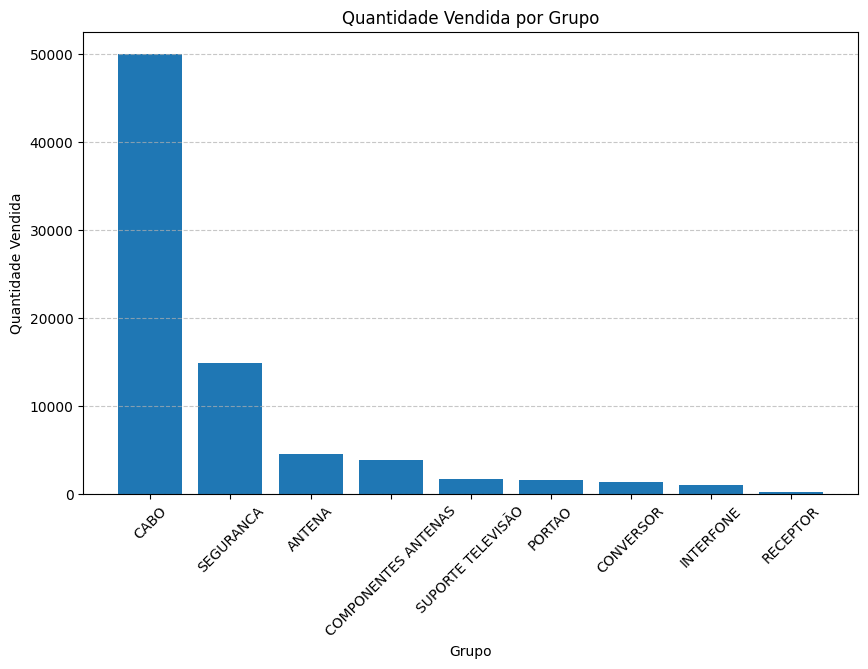

In [41]:
quandidade_vendida = banco_pred.groupby('grupo')['quantidade'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,6))
plt.bar(quandidade_vendida.index, quandidade_vendida.values)
plt.title('quantity sold by group')
plt.xlabel('Grupo')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.ylabel('quantity sold')
plt.show()

* here we can see that the group cable is quase a outlier estrutural, however, suthe sales are legitimate

---

### number of sales by group

In [42]:
# number of sales by group
banco_pred.groupby('grupo').size().sort_values(ascending=False)

grupo
CABO                   4779
ANTENA                 4270
COMPONENTES ANTENAS    3122
SEGURANCA              1406
PORTAO                 1363
CONVERSOR              1327
SUPORTE TELEVISÃO      1309
INTERFONE               382
RECEPTOR                199
dtype: int64

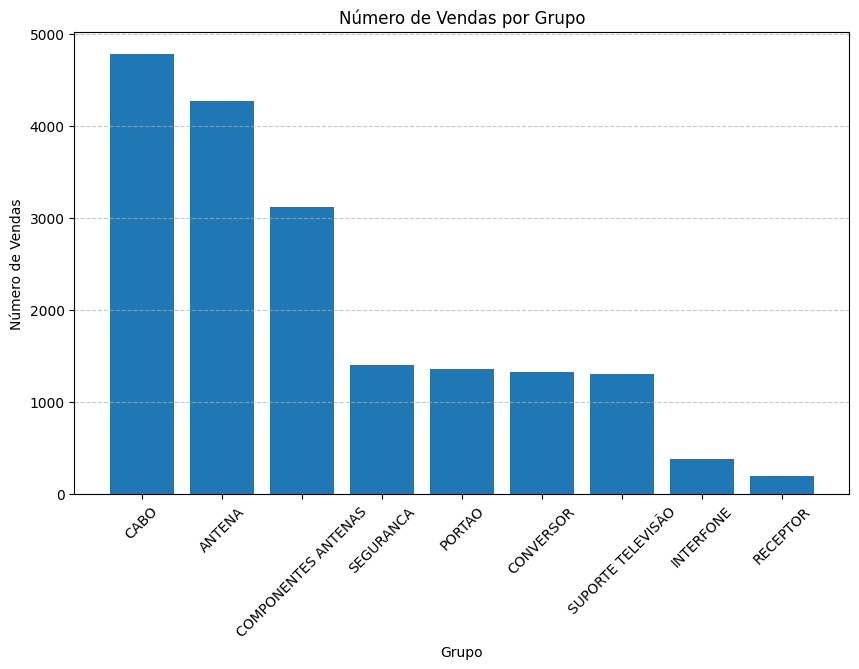

In [43]:
numero_vendas = banco_pred.groupby('grupo').size().sort_values(ascending=False)

plt.figure(figsize=(10,6))
plt.bar(numero_vendas.index, numero_vendas.values)
plt.title('number of sales by group')
plt.xlabel('Grupo')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.ylabel('number of sales')
plt.show()

---

### revenue by group

In [44]:
# revenue
banco_pred.groupby('grupo')['valor_total'].sum().sort_values(ascending=False)

grupo
ANTENA                 289776.0
SEGURANCA              283143.0
PORTAO                 275221.0
COMPONENTES ANTENAS    174592.0
CONVERSOR              148119.0
SUPORTE TELEVISÃO      120757.0
INTERFONE              117026.0
RECEPTOR                97007.0
CABO                    91083.7
Name: valor_total, dtype: float64

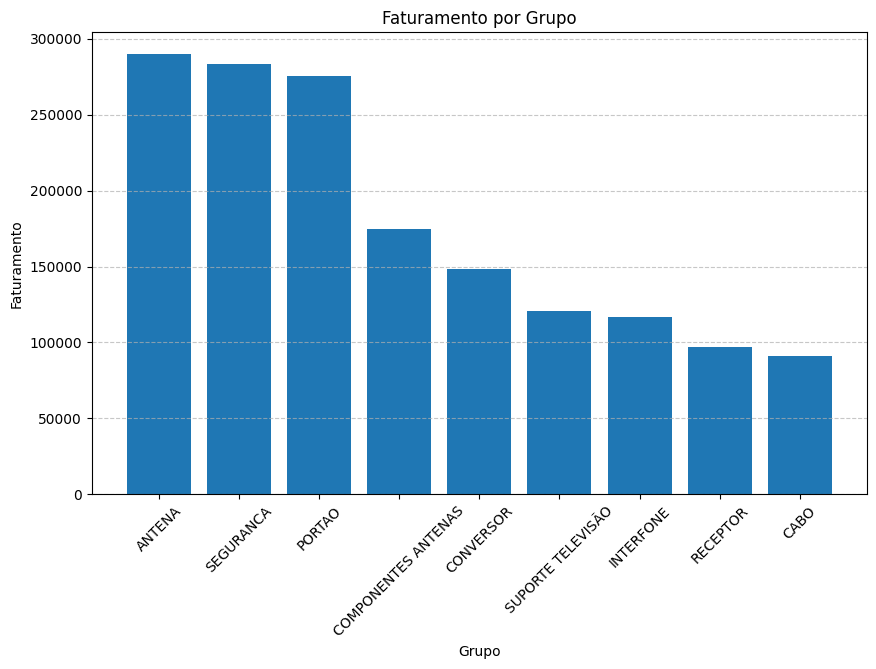

In [45]:
faturamento_por_grupo = banco_pred.groupby('grupo')['valor_total'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,6))
plt.bar(faturamento_por_grupo.index, faturamento_por_grupo.values)
plt.title('revenue by group')
plt.xlabel('Grupo')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.ylabel('Faturamento')
plt.show()

---

### Ticket-Médio by group

In [46]:
resumo_grupos = banco.groupby('grupo').agg(vendas=('grupo', 'size'), quantidade=('quantidade', 'sum'), 
                                           faturamento=('valor_total', 'sum')).sort_values('faturamento', ascending=False)


resumo_grupos

,vendas,quantidade,faturamento
grupo,,,
ANTENA,4270,4616.0,289776.0
SEGURANCA,1406,14938.0,283143.0
PORTAO,1363,1678.0,275221.0
COMPONENTES ANTENAS,3122,3944.0,174592.0
CONVERSOR,1327,1444.0,148119.0
SUPORTE TELEVISÃO,1309,1749.0,120757.0
INTERFONE,382,1103.0,117026.0
RECEPTOR,199,274.0,97007.0
CABO,4779,49964.0,91083.7


* here we can see that antenna is a group equilibrado, since possui a number of sales and quantity vendidas próximas, this shows that in a sale vende-if pelo less a antenna for este group.

* Outro aspecto interesting is the number of *sales* of the groups components antennas and cable, the which are complementary to the group antenna, since for perform a instalção, usas-if itens destes outros dois groups.

* however, cable is a group estruturalmente complex for forecasts, since seu revenue is relativamente low in relation to to the outros groups mas still thus has 3x more quantity sold of the that the segundo group more sold (security), the that demonstra that a sale ocorre majoritariamente by metragem and with low value aggregated. therefore, este dado serve only the complemento to the sales of antenna, for example.

* Similarmente, the group SEGURANCA apresenta few sales mas with large quantity and a high revenue, the that demonstra be sale of itens based in metragem and many quantities (cables of high tensão, hastes of about, cameras of security, entre outros); however, still thus is a group with high revenue (the segundo higher), being necessary a analysis more profunda sobre the products agregados to the group.

* also disso, groups the intercom, receiver, converter, PORTAO and bracket television if show interesting and relativamente equilibrados and bons for serem analisados from seasonality. 
    1) the group PORTAO and intercom possuem less sales that SEGURANCA, mas still thus possuem a high revenue, the that indica a high ticket médio. 
    2) the group converter possui a equilíbrio entre sales and quantities vendidas, with a revenue médio, the that demonstra be a variable boa for analysis.
    3) Similarmente, the group bracket television it is useful of be analyzed based in seasonality, being a bom candidato for understand sua seasonality and oferecer more demand in certos periods. 

In [47]:
resumo_grupos['ticket_medio'] = resumo_grupos['faturamento'] / resumo_grupos['vendas']

resumo_grupos.sort_values('ticket_medio', ascending=False)

,vendas,quantidade,faturamento,ticket_medio
grupo,,,,
RECEPTOR,199,274.0,97007.0,487.472362
INTERFONE,382,1103.0,117026.0,306.350785
PORTAO,1363,1678.0,275221.0,201.922964
SEGURANCA,1406,14938.0,283143.0,201.381935
CONVERSOR,1327,1444.0,148119.0,111.619442
SUPORTE TELEVISÃO,1309,1749.0,120757.0,92.251337
ANTENA,4270,4616.0,289776.0,67.863232
COMPONENTES ANTENAS,3122,3944.0,174592.0,55.923126
CABO,4779,49964.0,91083.7,19.059155


* observing-if the ticket médio, podemos note that the itens with more relevance in relation to to the revenue of the company are receiver, intercom, SEGURANCA and PORTAO.

* here it is useful note that, apesar of the groups antenna, COMPONENTE antenna and cable participarem of large quantities of sale, still thus not if show the the "carro chefe" of the company.

* the fato of the ticket médio of the PORTAO be praticamente igual to the of the group SEGURANCA sugere that itens of the group PORTAO possuem values more high and, possivelmente, are vendidos junto to the itens of SEGURANCA

---

### analysis of revenue of Itens by group

In [48]:
banco_pred[banco_pred['grupo'] == 'SEGURANCA'].groupby('descricao').agg(
        vendas=('descricao','size'),
        quantidade=('quantidade','sum'),
        faturamento=('valor_total','sum')
    ).sort_values('faturamento', ascending=False)

,vendas,quantidade,faturamento
descricao,,,
CONCERTINA 8 MT,119,419.0,55964.0
SUPORTE P/ CONCERTINA V 30CM,276,2425.0,39542.0
CONCERTINA SIMPLES 30 10 M RL 40 VT,67,208.0,23015.0
CENTRAL WIFI CERCA ELETRICA,36,36.0,15801.0
CENTRAL CERCA ELETRICA,53,53.0,14577.0
...,...,...,...
"BIG HASTE ESTICADOR 1,00MT 25X25",1,1.0,30.0
BIG HASTE ESTICADORA 23X23,1,1.0,30.0
SIRENE MONOTAL 1 SOM PRETA A3059,1,1.0,30.0


* here it is evident that the itens of SEGURANCA are of fato sold to the large units:
    1) cable of ACO: item sold pela metragem;
    2) bracket P/ CONCERTINA V 30CM: item sold by unit to the each 30 cm, variando therefore of acordo with the size of the site instalada;
    3) cable high TENSAO 5MM: item sold by metro for installations of cercas elétricas;
    4) cable of AÇO: item sold pela metragem and igual to the first;
    5) Outros itens voltados to the installations based in metragem of the site.

In [49]:
banco_pred[banco_pred['grupo'] == 'CABO'].groupby('descricao').agg(
        vendas=('descricao','size'),
        quantidade=('quantidade','sum'),
        faturamento=('valor_total','sum')
    ).sort_values('faturamento', ascending=False)

,vendas,quantidade,faturamento
descricao,,,
CABO COAXIAL RG 59,931,17089.0,32410.9
CABO DE REDE,140,4457.0,9677.0
CONECTOR ROSCA,743,4450.0,4586.0
CABO COAXIAL RG 6,104,1711.0,3553.0
CONECTOR PRESSAO RG06,322,1252.0,2991.0
...,...,...,...
CABO P2 RCA,1,1.0,5.0
EMENDA DE REDE,1,1.0,4.0
CONECTOR ROSCA RG06,1,2.0,4.0


* here also fica easy of observar that itens of the group cable are vendidos by metragem, the that dificulta a analysis of the quantity sold, mas still thus can ter correlations with the number of sales of the groups antenna and components antennas

In [50]:
banco_pred[banco_pred['grupo'] == 'components antennas'].groupby('descricao').agg(
        vendas=('descricao','size'),
        quantidade=('quantidade','sum'),
        faturamento=('valor_total','sum')
    ).sort_values('faturamento', ascending=False)

,vendas,quantidade,faturamento
descricao,,,
MODULADOR NAO ADJACENTE MNA TELEVOX,11,74.0,31065.0
AMPLIFICADOR DE LINHA 30DB,86,93.0,14811.0
"CANO 3/4""",357,446.0,10310.0
SUP CAVALETE 3/4,366,395.0,10114.0
MODULADOR AGIL,11,34.0,8500.0
...,...,...,...
CANO 1M 1,1,1.0,10.0
SUP PREGAR 1,1,2.0,10.0
CANO 1 P,1,1.0,8.0


In [51]:
banco_pred[banco_pred['grupo'] == 'PORTAO'].groupby('descricao').agg(
        vendas=('descricao','size'),
        quantidade=('quantidade','sum'),
        faturamento=('valor_total','sum')
    ).sort_values('faturamento', ascending=False)

,vendas,quantidade,faturamento
descricao,,,
CONTROLE PORTAO 433,286,443.0,19476.0
"MOTOR 1/2HP 4S 1,40MT PPA",10,10.0,13996.0
MOTOR BASCULANTE 4SEGUNDOS JETFLEX ABRE P/ DENTRO,9,9.0,11476.0
CENTRAL COLETIVA COLLECTIVE 8,11,11.0,9180.0
CENTRAL UNIVERSAL GAREN,74,74.0,8526.0
...,...,...,...
BASE DA CENTRAL BV MAX GAREN,1,1.0,17.0
PILHA CONTROLE PORTAO,3,3.0,15.0
"BARRA CREMALHEIRA 1,5MT",1,1.0,15.0


---

### revenue by group by year

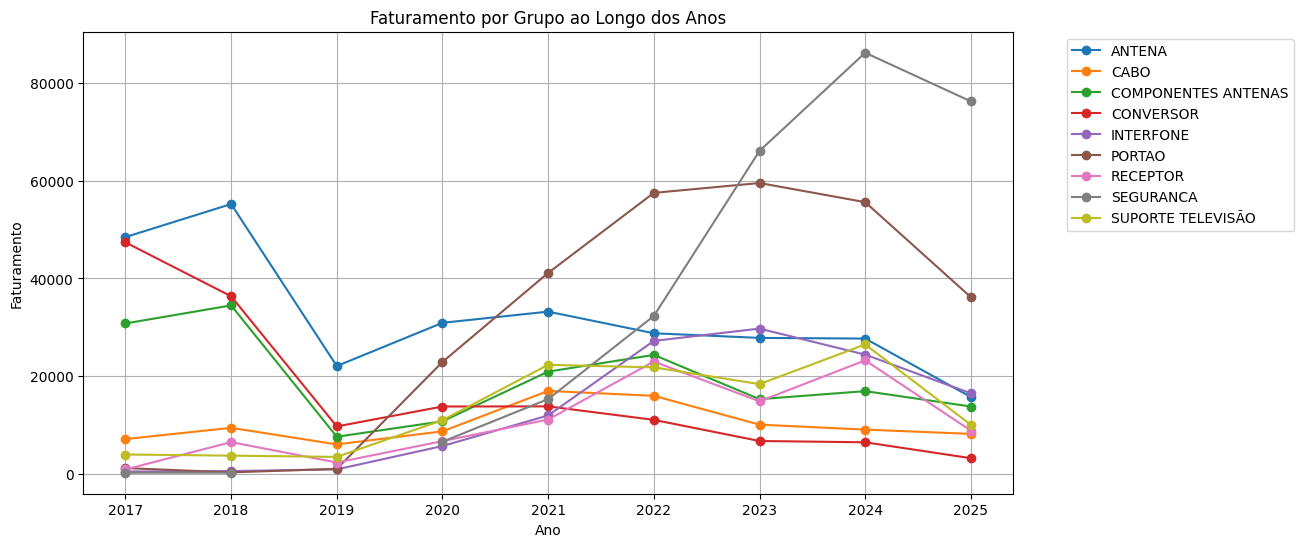

In [52]:
faturamento_grupo_ano = banco_pred.groupby([banco_pred['data_venda'].dt.year,'grupo'])['valor_total'].sum().reset_index()

faturamento_grupo_ano.columns = ['ano','grupo','faturamento']

pivot = faturamento_grupo_ano.pivot(
    index='ano',
    columns='grupo',
    values='faturamento'
)

pivot.plot(
    figsize=(12,6),
    marker='o'
)

plt.title('revenue by group to the long of the years')
plt.xlabel('Ano')
plt.ylabel('Faturamento')
plt.grid(True)
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)
plt.show()

---

### correlation entre the sales of different groups

In [53]:
# Série temporal monthly of revenue by group

faturamento_grupos = (
banco_pred
    .groupby([
        banco_pred['data_venda'].dt.to_period('M'), 'grupo'
    ])['valor_total'].sum().unstack(fill_value=0)
)
# unstack() cria a "table dynamics" a partir of the result of the groupby, where the index is a date of sale monthly 
# and the columns are the groups, with the values being the revenue total for each group in each month.    
# Ele is used for transformar the groups in columns, and fill_value=0 fills the values missing with zero.

faturamento_grupos.index = (
    faturamento_grupos.index.to_timestamp()
)

faturamento_grupos.head()


grupo,ANTENA,CABO,COMPONENTES ANTENAS,CONVERSOR,INTERFONE,PORTAO,RECEPTOR,SEGURANCA,SUPORTE TELEVISÃO
data_venda,,,,,,,,,
2017-02-01,1855.0,208.0,785.0,2380.0,0.0,120.0,0.0,0.0,105.0
2017-03-01,6337.0,817.0,2359.0,17785.0,0.0,40.0,0.0,0.0,205.0
2017-04-01,5770.0,706.0,1058.0,2620.0,0.0,40.0,0.0,0.0,180.0
2017-05-01,4805.0,688.0,1651.0,4295.0,0.0,5.0,0.0,0.0,445.0
2017-06-01,3752.0,372.0,784.0,4660.0,240.0,0.0,0.0,0.0,405.0


<Axes: xlabel='grupo', ylabel='grupo'>

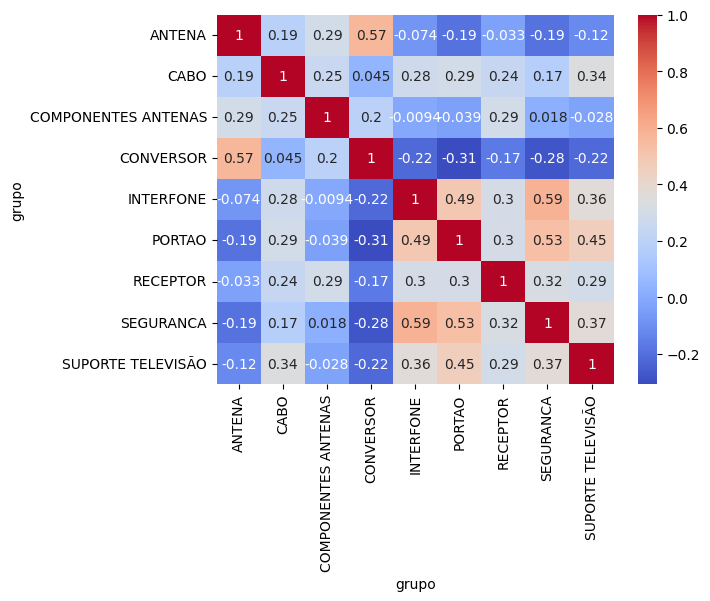

In [54]:
# correlation entre sales monthly of the groups

corr = faturamento_grupos.corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

---

## analysis Temporal

#### analyzing inconsistency of records

In [55]:
banco_pred['ano'] = banco_pred['data_venda'].dt.year
banco_pred['mes'] = banco_pred['data_venda'].dt.month

In [56]:
# count of the number of sales by year and month
vendas_mes_ano = (
    banco_pred.groupby(['ano', 'mes'])
    .size()
    .reset_index(name='qtd_vendas')
)
# reset_index(name='qtd_sales') transforma a série resultante of the count in a DataFrame, 
# where 'qtd_sales' is the nome of the nova coluna that contém the values of the count (.size()).
vendas_mes_ano.head()

,ano,mes,qtd_vendas
0,2017,2,106
1,2017,3,368
2,2017,4,166
3,2017,5,231
4,2017,6,185


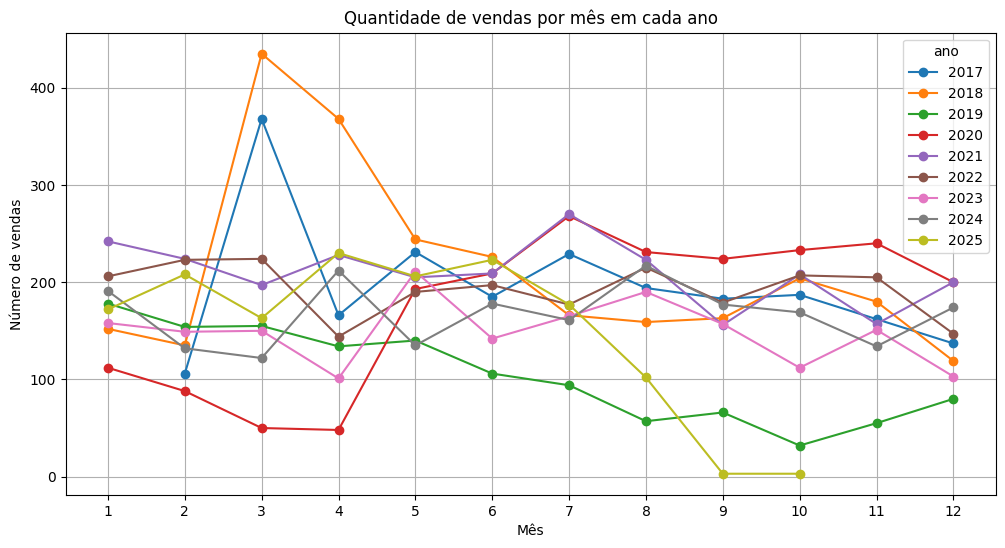

In [57]:
pivot = vendas_mes_ano.pivot(
    index='mes',
    columns='ano',
    values='qtd_vendas'
)

pivot.plot(figsize=(12,6), marker='o')

plt.title('quantity of sales by month in each year')
plt.xlabel('Mês')
plt.ylabel('number of sales')
plt.xticks(range(1,13))
plt.grid(True)
plt.show()

* analysis of the gráfico of quantity of sales by month in each year:
    1) the year of 2017 inicia only in fevereiro;
    2) the year of 2025 possui a decline drástica após the month 08. observing the dataset of date, we note a low number of records of sales in the months 09 and 10 of the year of 2025, the which were comunicados pela própria company that were months of trocas of dataset of date of records, being interesting removê-los of the dataset of date for not create noise in the séries temporais.

* analyses important:
    1) 2017 and 2018 possuem a high value of sale in the month 03, mas seguidos of high variability. 
    2) 2019 was marcado by declines throughout of todo year.
    3) 2020 despencou sales of 01 a 04 (pandemia), mas with crescente number of sales (possivelmente due to installation of TVs with bracket and itens of security since tinham many pessoas in casa).
    4) 2021, 2022, 2023 and 2024 if show relativamente equilibrados and with trend horizontal.
    5) 2025 possui a decline brusca due to falta of records.

In [58]:
print(f'Primeira data de venda registrada: {banco_pred["data_venda"].min()}')
print(f'Última data de venda registrada: {banco_pred["data_venda"].max()}')

Primeira data de venda registrada: 2017-02-14 00:00:00
Última data de venda registrada: 2025-10-30 00:00:00


In [59]:
banco_pred.groupby(
    banco_pred['data_venda'].dt.to_period('M')
).size()

data_venda
2017-02    106
2017-03    368
2017-04    166
2017-05    231
2017-06    185
          ... 
2025-06    223
2025-07    177
2025-08    102
2025-09      3
2025-10      3
Freq: M, Length: 105, dtype: int64

* the can-if note, there are only 3 sales registras in the month 09/2025 and 3 sales in 10/2025, it is useful retira-los for not gerar noise.

In [60]:
# Retirando the records of setembro and outubro of 2025
banco_pred = banco_pred[
    ~(
        (banco_pred['data_venda'].dt.year == 2025)
        &
        (banco_pred['data_venda'].dt.month.isin([9, 10]))
    )
].copy()

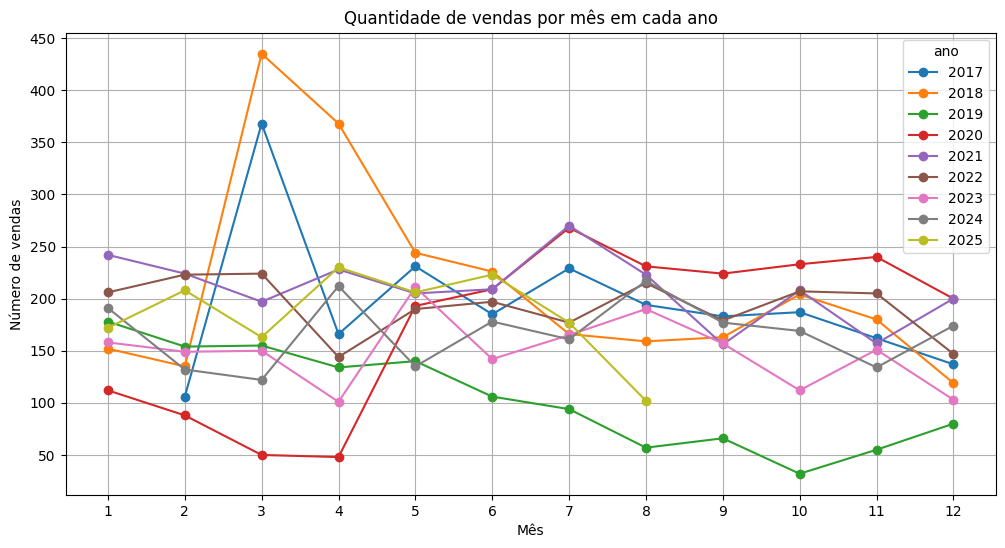

In [ ]:
# Após remover the records of 2025
vendas_mes_ano_1 = (
    banco_pred.groupby(['ano', 'mes'])
    .size()
    .reset_index(name='qtd_vendas')
)

pivot_1 = vendas_mes_ano_1.pivot(
    index='mes',
    columns='ano',
    values='qtd_vendas'
)

pivot_1.plot(figsize=(12,6), marker='o')

plt.title('quantity of sales by month in each year')
plt.xlabel('Mês')
plt.ylabel('number of sales')
plt.xticks(range(1,13))
plt.grid(True)
plt.show()

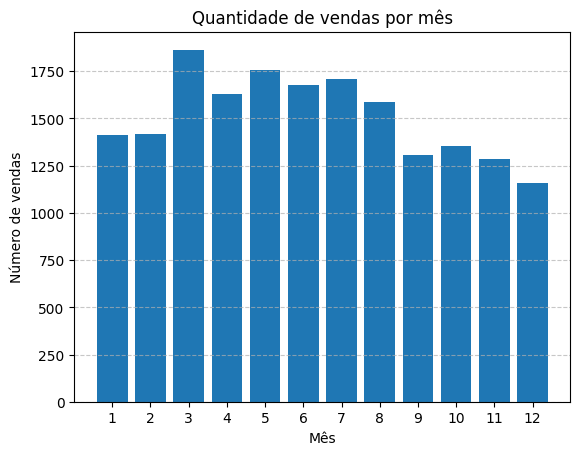

In [62]:
vendas_por_mes = (
    banco_pred.groupby(
        banco_pred['data_venda'].dt.month
    )
    .size()
)

plt.bar(vendas_por_mes.index, vendas_por_mes.values)
plt.title('quantity of sales by month')
plt.xlabel('Mês')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(range(1,13))
plt.ylabel('number of sales')
plt.show()

* we note that there are a lower demand pelos products of the company in the start of the year (janeiro and fevereiro), also of the end of the year (setembro, outubro, novembro, dezembro), a reflexo expected considering that a higher parte of the população brasileira viaja nessas épocas (férias), the that acaba refletindo in baixas purchases of the market econômico here considerado.

* however, there are a bom equilíbrio in the number of sales entre the months of março and agosto, the that shows serem the periods of higher compras neste market.

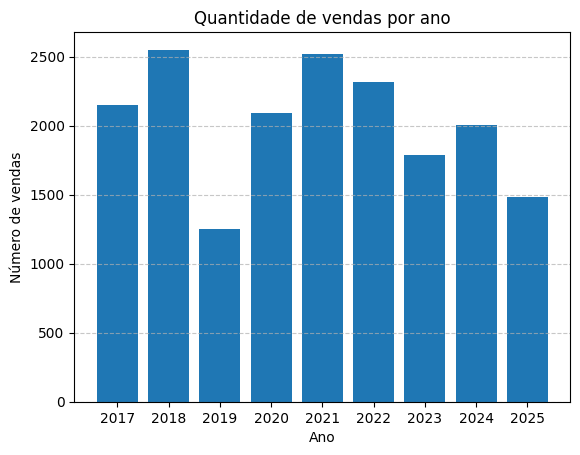

In [63]:
vendas_por_ano = (
    banco_pred.groupby(
        banco_pred['data_venda'].dt.year
    )
    .size()
)

plt.bar(vendas_por_ano.index, vendas_por_ano.values)
plt.title('quantity of sales by year')
plt.xlabel('Ano')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(vendas_por_ano.index)
plt.ylabel('number of sales')
plt.show()

* Neste gráfico podemos observar that 2019 was the worse year for a company, ficando atrás still of the year initial of the pandemia (2020), talvez sofrendo reflexo of eventuais questões políticas and econômicas in the país. will be necessary evaluate with more rigor. also disso, the year of 2025 shows low number of record, result of a comportamento espero due to migration of system.

### revenue

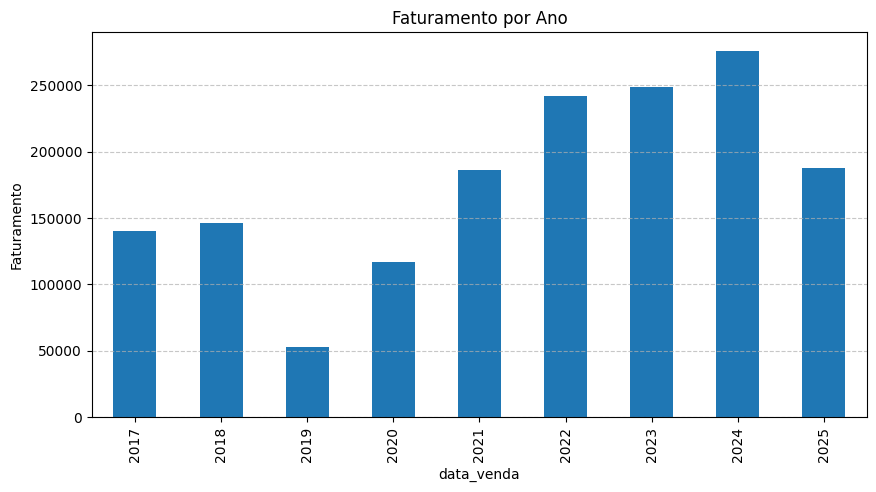

In [64]:
faturamento_ano = (
    banco_pred.groupby(
        banco_pred['data_venda'].dt.year
    )['valor_total']
    .sum()
)

faturamento_ano.plot(
    kind='bar',
    figsize=(10,5)
)
plt.ylabel('Faturamento')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.title('revenue by year')
plt.show()

* the revenue by year complements the information contidas in the quantity of sales by year:
    1) Apesar of the number of sales of 2017 be lower that 2018, still thus esses years possuem faturamentos close.
    2) the revenue of the year of 2019 was the worse, reflexo of the lower number of sales.
    3) Houve a comportamento crescente in the revenue of the company a partir of the year of 2019, being initially lower in 2020, result expected due to pandemia.
    4) by end, a decline in the revenue in 2025 is expected due to falta of 4 months of records (9, 10, 11 and 12).

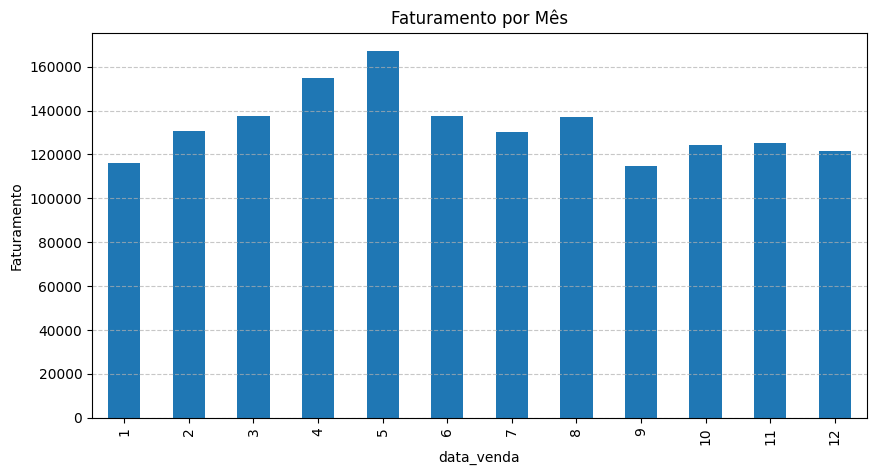

In [65]:
faturamento_mes = (
    banco_pred.groupby(
        banco_pred['data_venda'].dt.month
    )['valor_total']
    .sum()
)

faturamento_mes.plot(
    kind='bar',
    figsize=(10,5)
)
plt.title('revenue by month')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylabel('Faturamento')
plt.show()

* of forma similar, the revenue monthly complements a quantity sold in the months throughout of the period estudado:
    1) there are a equilíbrio in the number of sales entre the months of março and agosto, mas the revenue tende a grow até the month of higher and cair throughout of the year, being lower in the extremos (start and end of year), result expected due to seasonality of férias of the Brasil.

#### Série temporal monthly of revenue

* revenue monthly throughout of the years -> Série Temporal
    1) there is trend?
    2) there is seasonality?
    3) there is noise?

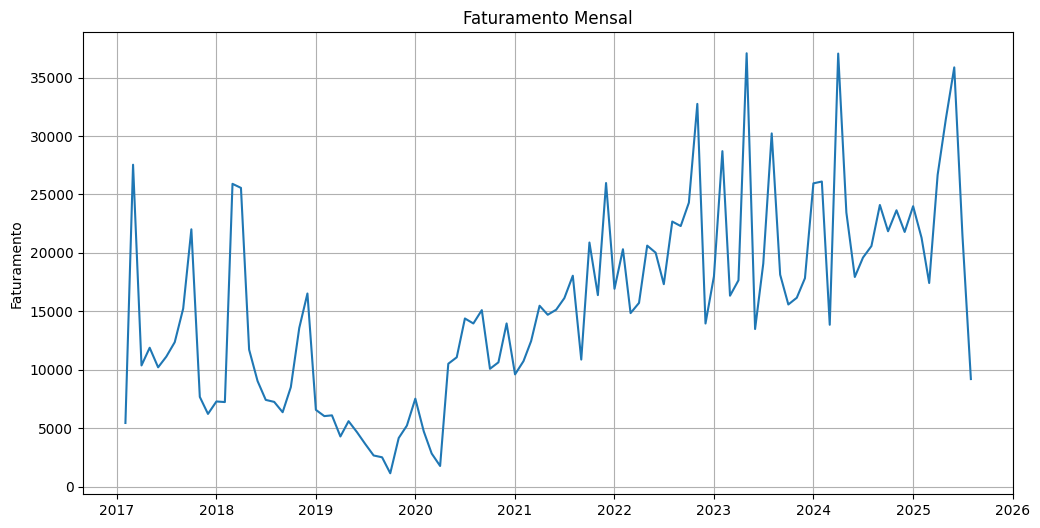

In [74]:
faturamento_mensal = (
    banco_pred.groupby(
        banco_pred['data_venda'].dt.to_period('M')
    )['valor_total']
    .sum()
)

faturamento_mensal.index = (
    faturamento_mensal.index.to_timestamp()
)

plt.figure(figsize=(12,6))
plt.plot(faturamento_mensal)
plt.grid(True)
plt.title('revenue monthly')
plt.ylabel('Faturamento')
plt.show()

* there is trend -> growth

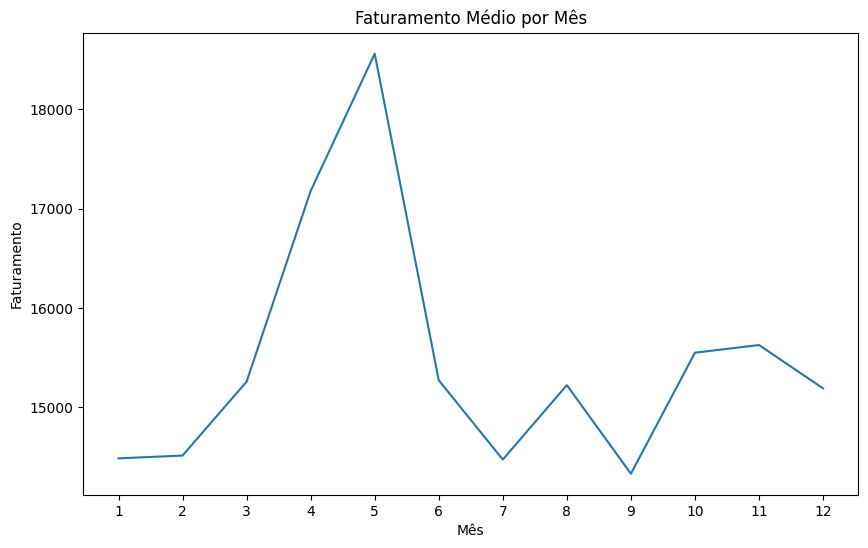

In [ ]:
fat_mes_ano = (
    banco_pred
    .assign(
        ano=banco_pred['data_venda'].dt.year,
        mes=banco_pred['data_venda'].dt.month
    )
    .groupby(['ano','mes'])['valor_total']
    .sum()
    .reset_index() # .reset_index() is used for transformar the index of the result 
    # of the groupby in columns regulares
)

faturamento_medio_mes = (
    fat_mes_ano.groupby('mes')['valor_total']
    .mean()
)

plt.figure(figsize=(10,6))
plt.plot(faturamento_medio_mes.index, faturamento_medio_mes.values)
plt.title('revenue Médio by month')
plt.xlabel('Mês')
plt.xticks(range(1,13))
plt.ylabel('Faturamento')
plt.show()

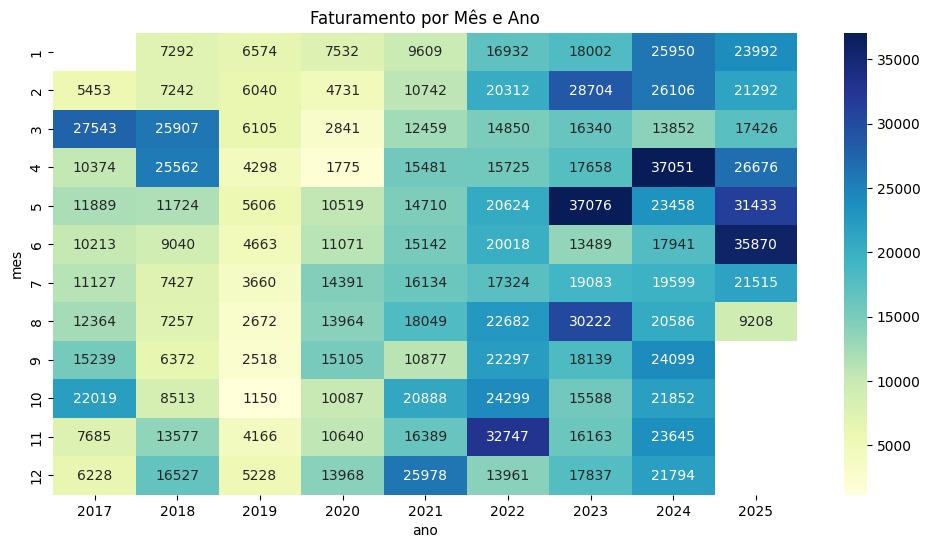

In [80]:
pivot_fat = fat_mes_ano.pivot(
    index='mes',
    columns='ano',
    values='valor_total'
)

plt.figure(figsize=(12,6))
sns.heatmap(
    pivot_fat,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu'
)

plt.title('revenue by month and year')
plt.show()

* here we can see that:
    1) the revenue médio is higher in the months 4 and 5.
    2) the revenue grew very após the month 5 of the year of 2021.
    3) we notice that of the year of 2022 for frente the revenue if estabiliza

#### there is seasonality após remover a trend?

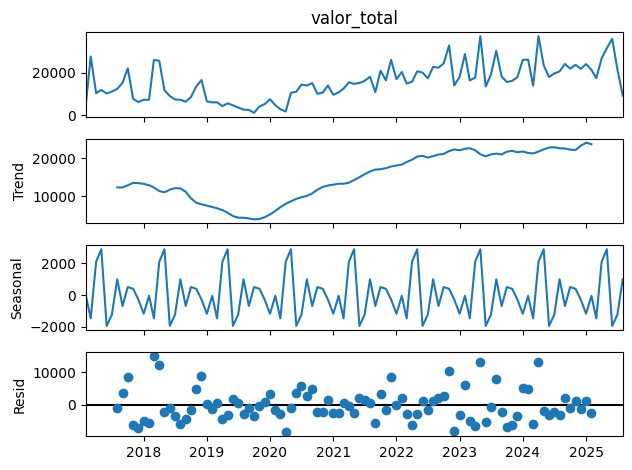

In [86]:
decomp_add = seasonal_decompose(
    faturamento_mensal,
    model='additive',
    period=12
)

decomp_add.plot();

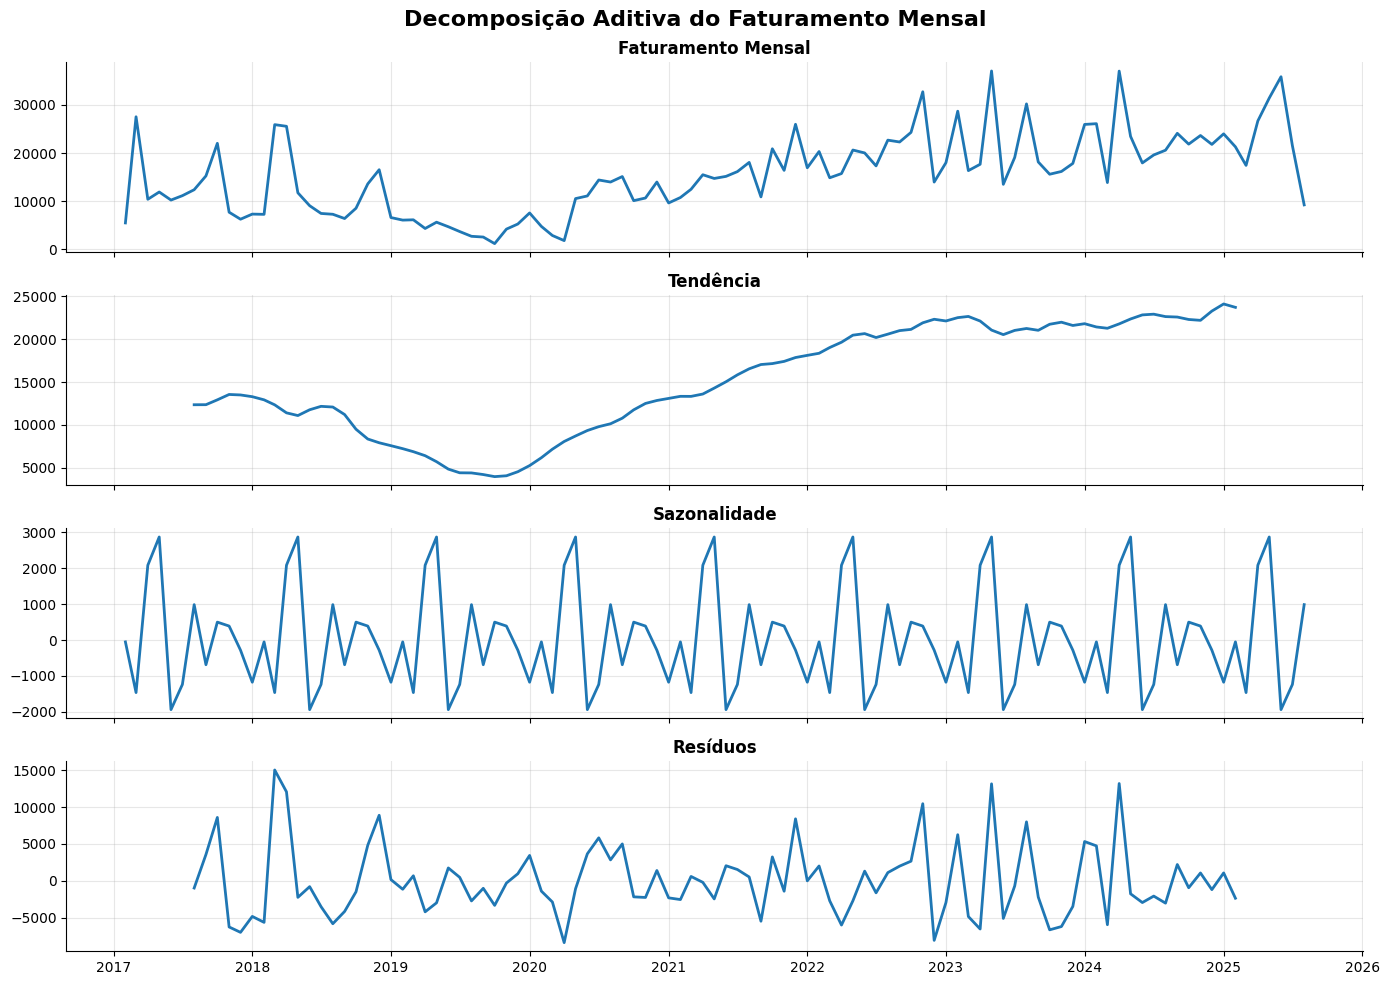

In [87]:
import matplotlib.dates as mdates

fig, axes = plt.subplots(
    4, 1,
    figsize=(14, 10),
    sharex=True
)

componentes = [
    faturamento_mensal,
    decomp_add.trend,
    decomp_add.seasonal,
    decomp_add.resid
]

titulos = [
    'revenue monthly',
    'Tendência',
    'Sazonalidade',
    'Resíduos'
]


for ax, serie, titulo in zip(axes, componentes, titulos):
    ax.plot(
        serie.index,
        serie.values,
        linewidth=2
    )

    ax.set_title(
        titulo,
        fontsize=12,
        fontweight='bold'
    )

    ax.grid(
        True,
        alpha=0.3
    )

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


axes[-1].xaxis.set_major_locator(
    mdates.YearLocator()
)

axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter('%Y')
)

plt.suptitle(
    'decomposition additive of the revenue monthly',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()

plt.show()

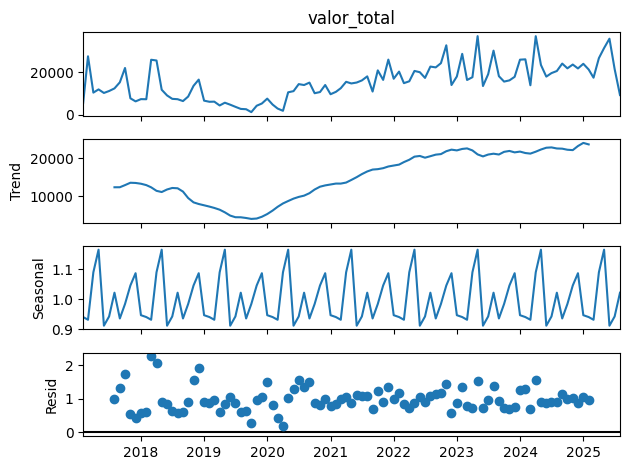

In [83]:
decomp_mul = seasonal_decompose(
    faturamento_mensal,
    model='multiplicative',
    period=12
)

decomp_mul.plot();

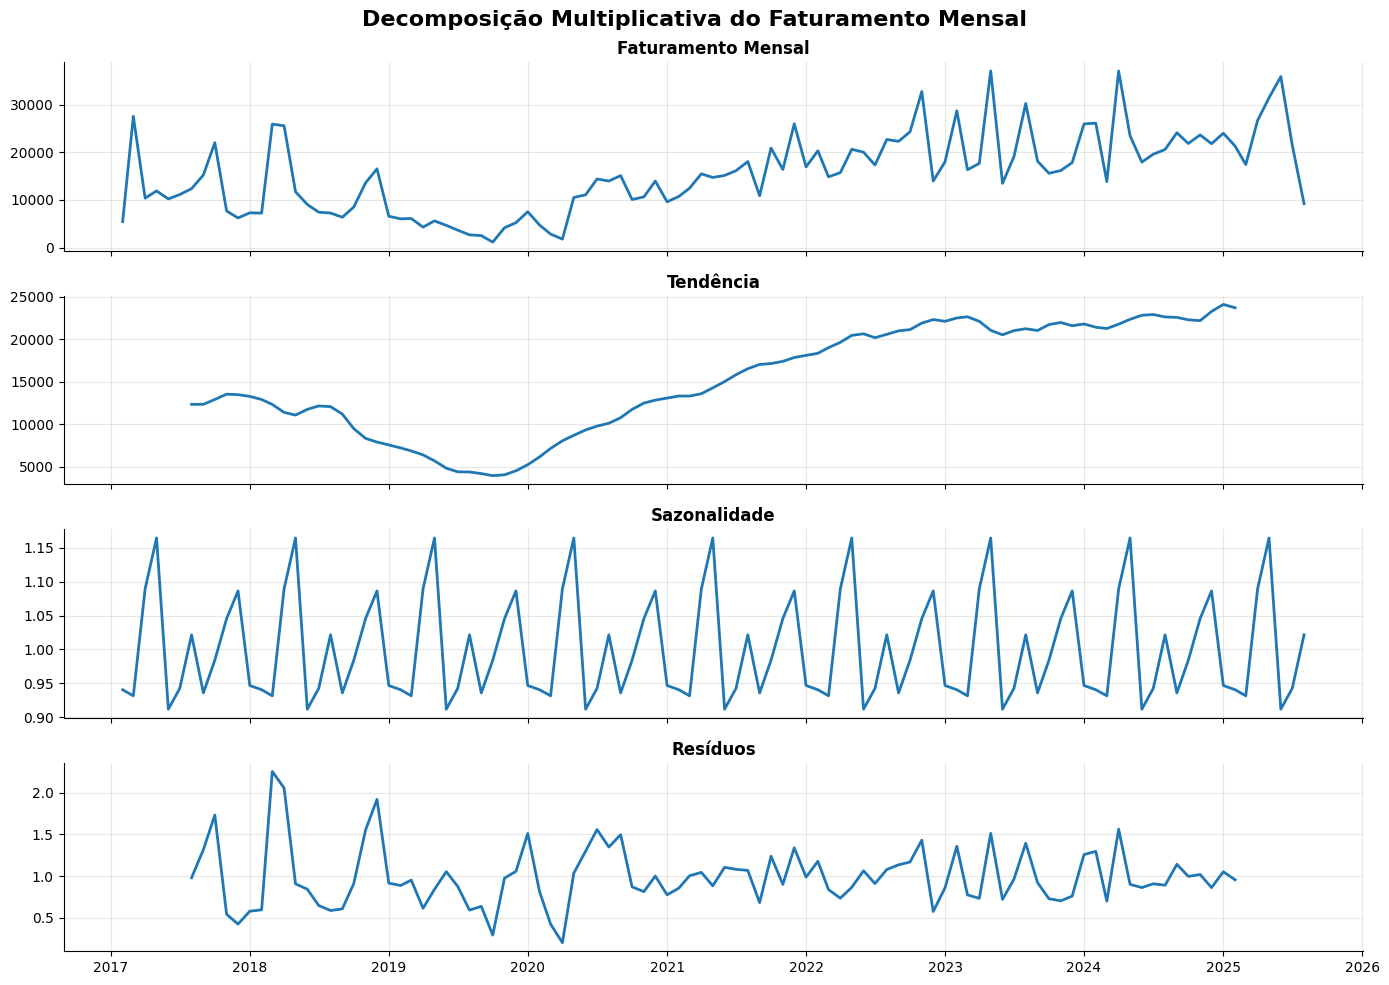

In [88]:
import matplotlib.dates as mdates

fig, axes = plt.subplots(
    4, 1,
    figsize=(14, 10),
    sharex=True
)

componentes = [
    faturamento_mensal,
    decomp_mul.trend,
    decomp_mul.seasonal,
    decomp_mul.resid
]

titulos = [
    'revenue monthly',
    'Tendência',
    'Sazonalidade',
    'Resíduos'
]


for ax, serie, titulo in zip(axes, componentes, titulos):
    ax.plot(
        serie.index,
        serie.values,
        linewidth=2
    )

    ax.set_title(
        titulo,
        fontsize=12,
        fontweight='bold'
    )

    ax.grid(
        True,
        alpha=0.3
    )

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


axes[-1].xaxis.set_major_locator(
    mdates.YearLocator()
)

axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter('%Y')
)

plt.suptitle(
    'decomposition multiplicative of the revenue monthly',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()

plt.show()

indices_seasonal = pd.DataFrame({
    'mes': range(1, 13),
    'indice_seasonal': decomp_add.seasonal[:12].values
})

indices_seasonal

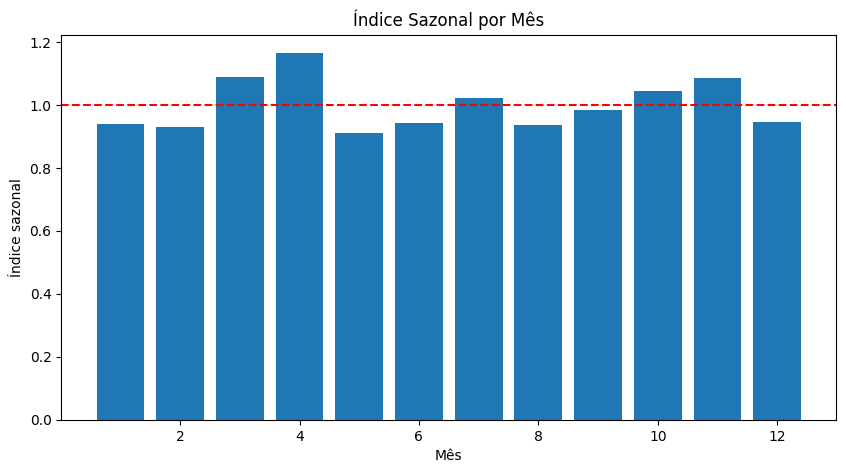

In [100]:
plt.figure(figsize=(10,5))

plt.bar(
    indices_sazonais['mes'],
    indices_sazonais['indice_sazonal']
)

plt.axhline(
    y=1,
    color='red',
    linestyle='--'
)

plt.xlabel('Mês')
plt.ylabel('index seasonal')
plt.title('index seasonal by month')

plt.show()

<Axes: xlabel='mes', ylabel='valor_total'>

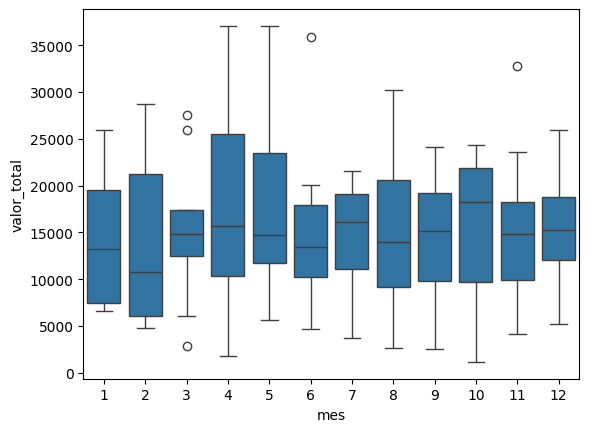

In [101]:
sns.boxplot(
    data=fat_mes_ano,
    x='mes',
    y='valor_total'
)

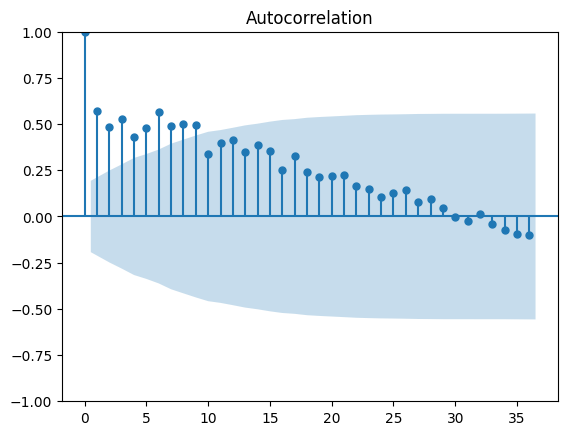

In [102]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(faturamento_mensal, lags=36)
plt.show()

In [103]:
from statsmodels.tsa.stattools import adfuller

resultado = adfuller(faturamento_mensal)

print('ADF:', resultado[0])
print('p-value:', resultado[1])

ADF: -0.5864523819550136
p-value: 0.8740139429160403


In [106]:
serie_diff = faturamento_mensal.diff().dropna()

resultado = adfuller(serie_diff)

print('p-value with diferenciação:', resultado[1])

p-value com diferenciação: 9.115555750407747e-09


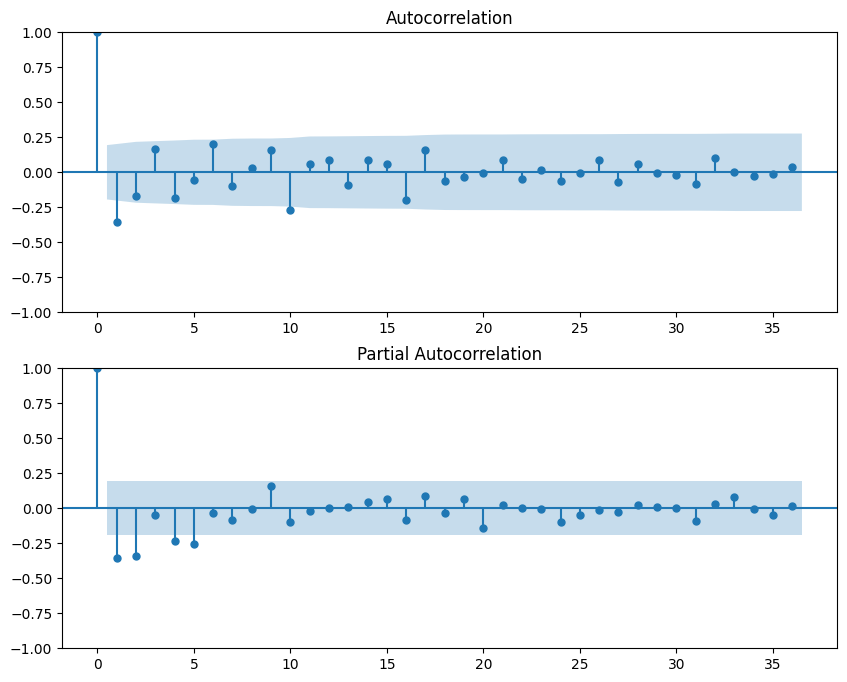

In [173]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(10,8))

plot_acf(serie_diff, lags=36, ax=ax[0])
plot_pacf(serie_diff, lags=36, ax=ax[1])

plt.show()

---

## algorithms of forecast

In [109]:
faturamento_mensal = (
    banco_pred
    .groupby(
        banco_pred['data_venda'].dt.to_period('M')
    )['valor_total']
    .sum()
)

faturamento_mensal.index = (
    faturamento_mensal.index.to_timestamp()
)

In [111]:
n = len(faturamento_mensal)

treino = faturamento_mensal[:int(0.8*n)]
teste = faturamento_mensal[int(0.8*n):]

### Baseline (Naive Forecast)

In [112]:
y_train = treino
y_test = teste

y_pred_naive = y_test.shift(1)

# first forecast usa the last value of the training
y_pred_naive.iloc[0] = y_train.iloc[-1]

In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

mae = mean_absolute_error(y_test, y_pred_naive)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_naive))

print(mae)
print(rmse)

6210.795238095238
8486.483446746643


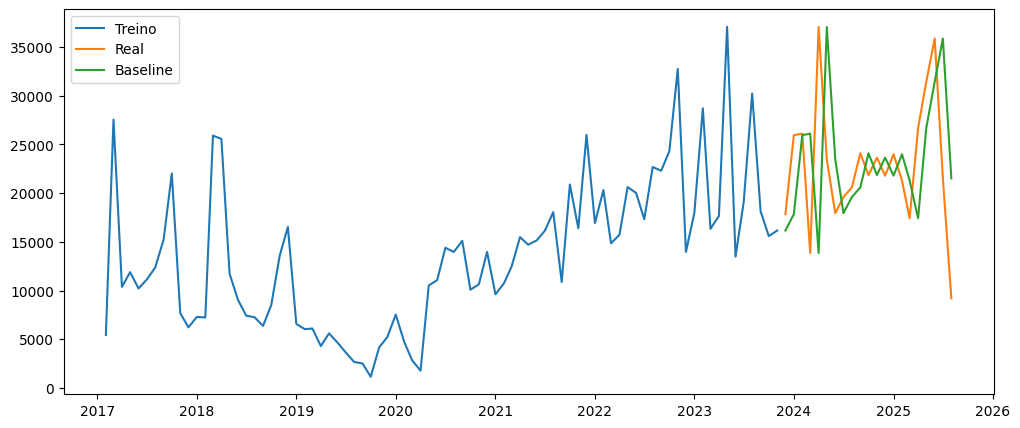

In [114]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(y_train.index, y_train, label='Treino')
plt.plot(y_test.index, y_test, label='Real')
plt.plot(y_pred_naive.index, y_pred_naive, label='Baseline')

plt.legend()
plt.show()

### Holt-Winters

In [115]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

modelo_hw = ExponentialSmoothing(
    treino,
    trend='add',
    seasonal='mul',
    seasonal_periods=12
)

ajuste_hw = modelo_hw.fit()

pred_hw = ajuste_hw.forecast(len(teste))

c:\Users\Marino\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


In [116]:
mae_hw = mean_absolute_error(teste, pred_hw)
rmse_hw = np.sqrt(mean_squared_error(teste, pred_hw))

print(f'MAE: {mae_hw:.3f}')
print(f'RMSE: {rmse_hw:.3f}')

MAE: 5740.184
RMSE: 7615.870


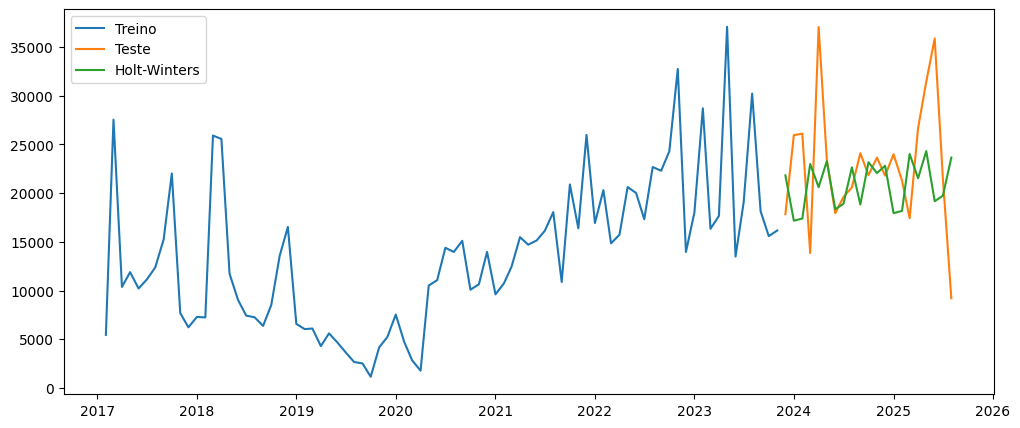

In [117]:
plt.figure(figsize=(12,5))

plt.plot(treino.index, treino, label='Treino')
plt.plot(teste.index, teste, label='Teste')
plt.plot(pred_hw.index, pred_hw, label='Holt-Winters')

plt.legend()
plt.show()

### ARIMA

In [146]:
from statsmodels.tsa.arima.model import ARIMA

modelo = ARIMA(
    treino,
    order=(0,1,1)
)

ajuste = modelo.fit()

pred_arima = ajuste.forecast(
    steps=len(teste)
)

In [147]:
mae_arima = mean_absolute_error(teste, pred_arima)
rmse_arima = np.sqrt(mean_squared_error(teste, pred_arima))

print(f'MAE: {mae_arima:.3f}')
print(f'RMSE: {rmse_arima:.3f}')

MAE: 5414.816
RMSE: 7204.969


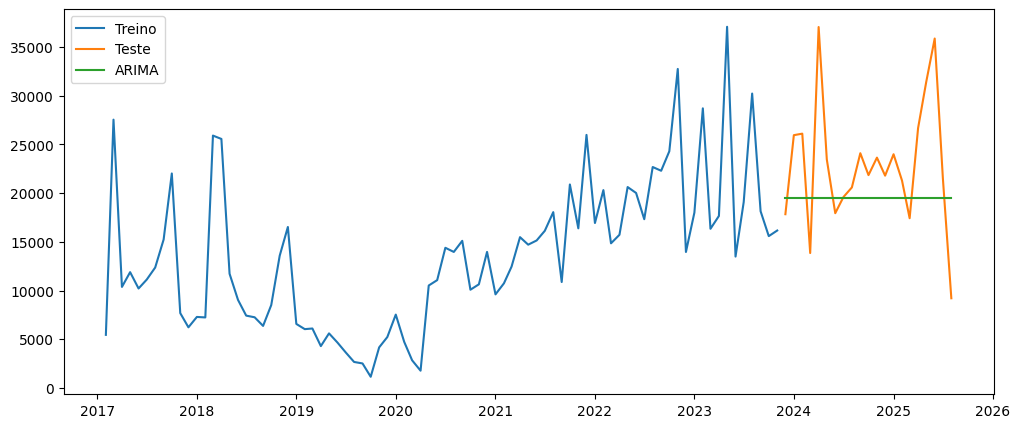

In [148]:
plt.figure(figsize=(12,5))

plt.plot(treino.index, treino, label='Treino')
plt.plot(teste.index, teste, label='Teste')
plt.plot(pred_arima.index, pred_arima, label='ARIMA')

plt.legend()
plt.show()

### Auto-Arima

In [167]:
from pmdarima import auto_arima

modelo_arima = auto_arima(
    treino,
    seasonal=True,
    m=12,
    stepwise=True,
    trace=True,
    suppress_warnings=True
)

print(modelo_arima.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=1649.775, Time=0.18 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=1675.506, Time=0.01 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=1666.784, Time=0.04 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=1647.099, Time=0.04 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=1673.538, Time=0.01 sec
 ARIMA(0,1,1)(0,0,0)[12] intercept   : AIC=1646.094, Time=0.02 sec
 ARIMA(0,1,1)(1,0,0)[12] intercept   : AIC=1647.470, Time=0.04 sec
 ARIMA(0,1,1)(1,0,1)[12] intercept   : AIC=1647.770, Time=0.08 sec
 ARIMA(1,1,1)(0,0,0)[12] intercept   : AIC=1647.605, Time=0.02 sec
 ARIMA(0,1,2)(0,0,0)[12] intercept   : AIC=1647.417, Time=0.06 sec
 ARIMA(1,1,0)(0,0,0)[12] intercept   : AIC=1667.087, Time=0.01 sec
 ARIMA(1,1,2)(0,0,0)[12] intercept   : AIC=inf, Time=0.08 sec
 ARIMA(0,1,1)(0,0,0)[12]             : AIC=1644.703, Time=0.01 sec
 ARIMA(0,1,1)(1,0,0)[12]             : AIC=1645.875, Time=0.03 sec
 ARIMA(0,1,1)(0,0,1)[12]

In [168]:
pred_arima = modelo_arima.predict(
    n_periods=len(teste)
)

In [169]:
pred_arima = pd.Series(
    pred_arima,
    index=teste.index
)

In [170]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

import numpy as np

mae = mean_absolute_error(
    teste,
    pred_arima
)

rmse = np.sqrt(
    mean_squared_error(
        teste,
        pred_arima
    )
)

mape = (
    np.abs(
        (teste - pred_arima)
        / teste
    ).mean()
) * 100

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")

MAE:  5414.82
RMSE: 7204.97
MAPE: 24.11%


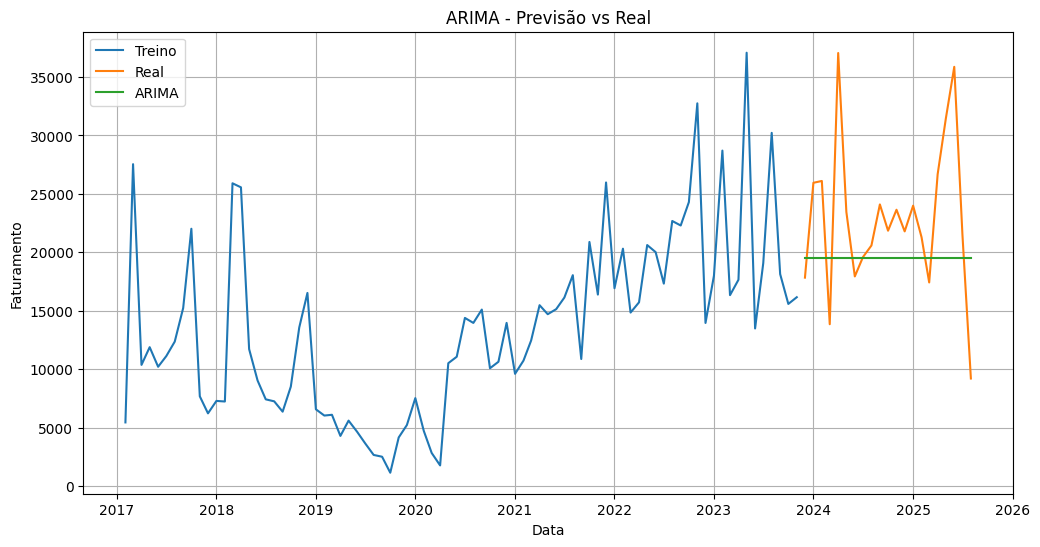

In [171]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(
    treino.index,
    treino,
    label='Treino'
)

plt.plot(
    teste.index,
    teste,
    label='Real'
)

plt.plot(
    pred_arima.index,
    pred_arima,
    label='ARIMA'
)

plt.title('ARIMA - forecast vs Real')
plt.ylabel('Faturamento')
plt.xlabel('Data')

plt.legend()
plt.grid(True)

plt.show()

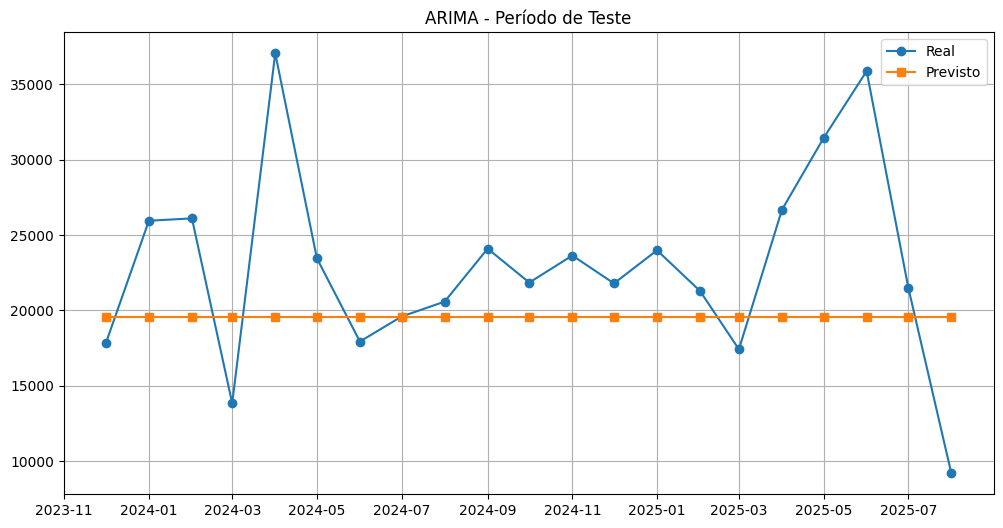

In [172]:
plt.figure(figsize=(12,6))

plt.plot(
    teste.index,
    teste,
    marker='o',
    label='Real'
)

plt.plot(
    pred_arima.index,
    pred_arima,
    marker='s',
    label='Previsto'
)

plt.title('ARIMA - period of test')

plt.legend()
plt.grid(True)

plt.show()